# Using the `tommos-adapter` in Ubermag

This notebook shows how to use the `tommos-adapter` for Ubermag.

In [1]:
import mammos_entity as me
import matplotlib.pyplot as plt
import micromagneticmodel as mm
import numpy as np
import pyvista as pv

import tommos_adapter as ta

## Generate mesh

We use `tommos` to generate the mesh:

In [2]:
!tommos mesh --geom box --extent 20,20,20 --h 2 --out-name cube

[ok] Wrote data: cube.npz (nodes=3284, tets=15109)
[ok] Wrote visualization: cube.vtu (cell_data: mat_id)


## Initialize System

We start with a `System` object, with name `hysteresis`.

In [3]:
system = mm.System(name="loop")

## Define magnetization

The generated mesh uses nanometres and stores TOMMOS material identifiers in `mat_id`. For the adapter, coordinates are converted to metres and the cell-data array is renamed to `region_id`:

In [4]:
mesh = pv.read("cube.vtu")
mesh.points *= ta.scripts.DEFAULT_MESH_UNIT
id_array = mesh.get_array("mat_id")
mesh.cell_data["region_id"] = id_array
mesh.cell_data.remove("mat_id")  # Remove the old `mat_id` cell data.
mesh

UnstructuredGrid (0x7fcd28bdfb80)
  N Cells:    15109
  N Points:   3284
  X Bounds:   -1.000e-08, 1.000e-08
  Y Bounds:   -1.000e-08, 1.000e-08
  Z Bounds:   -1.000e-08, 1.000e-08
  N Arrays:   1

We define an initial magnetization, constant $(0, 1/\sqrt(2), 1/\sqrt(2))$

In [5]:
m = np.zeros((mesh.n_points, 3), dtype=np.float32)
m[:, [1, 2]] = 1 / np.sqrt(2)
m

array([[0.        , 0.70710677, 0.70710677],
       [0.        , 0.70710677, 0.70710677],
       [0.        , 0.70710677, 0.70710677],
       ...,
       [0.        , 0.70710677, 0.70710677],
       [0.        , 0.70710677, 0.70710677],
       [0.        , 0.70710677, 0.70710677]],
      shape=(3284, 3), dtype=float32)

We add the magnetization vectors to the mesh as a point-data vector field and the Spontaneous Polarization property as cell constant.

In [6]:
mesh.point_data["m"] = m
Js = 1.76  # spontaneous polarization in tesla
Ms_array = (Js / mm.consts.mu0) * np.ones(mesh.n_cells)
mesh.cell_data["Ms"] = Ms_array
system.m = mesh
mesh

UnstructuredGrid (0x7fcd28bdfb80)
  N Cells:    15109
  N Points:   3284
  X Bounds:   -1.000e-08, 1.000e-08
  Y Bounds:   -1.000e-08, 1.000e-08
  Z Bounds:   -1.000e-08, 1.000e-08
  N Arrays:   3

## Define energy terms

Energy terms include intrinsic properties

In [7]:
A = 1e-12  # exchange stiffness constant in J/m
K = 4e5  # first uniaxial anisotropy constant in J/m^3
u = (0, 0, 1)  # anisotropy unit axis
system.energy = mm.Exchange(A=A) + mm.UniaxialAnisotropy(K=K, u=u) + mm.Demag()
system.energy

Exchange(A=1e-12) + UniaxialAnisotropy(K=400000.0, u=(0, 0, 1)) + Demag()

## Define driver and hysteresis parameters

Next, we define the driver. The initialization does not need any argument.

In [8]:
hd = ta.HysteresisDriver()
hd

HysteresisDriver()

Let us simulate hysteresis between $-2$ Tesla and $1$ Tesla applied along the $x$-direction in steps of $0.2$ Tesla:

In [9]:
Hmin_1 = [-3 / mm.consts.mu0, 0, 0]
Hmax_1 = [+3 / mm.consts.mu0, 0, 0]
Hmin_2 = [+3 / mm.consts.mu0, 0, 0]
Hmax_2 = [-3 / mm.consts.mu0, 0, 0]
n = 31

We prepare the `Hsteps` object defining the field protocol as the two branches of the hysteresis loop

In [10]:
Hsteps = [[Hmin_1, Hmax_1, n], [Hmin_2, Hmax_2, n]]

Now we execute the hysteresis loop.

In [11]:
hd.drive(system, Hsteps=Hsteps)

Running Tommos (TommosRunner)[2026-10-27T11:15:09]... (9.2 s)
Running Tommos (TommosRunner)[2026-10-27T11:15:18]... (7.9 s)


In [12]:
system.m

UnstructuredGrid (0x7fcd28bdfb80)
  N Cells:    15109
  N Points:   3284
  X Bounds:   -1.000e-08, 1.000e-08
  Y Bounds:   -1.000e-08, 1.000e-08
  Z Bounds:   -1.000e-08, 1.000e-08
  N Arrays:   3

## Hysteresis plot

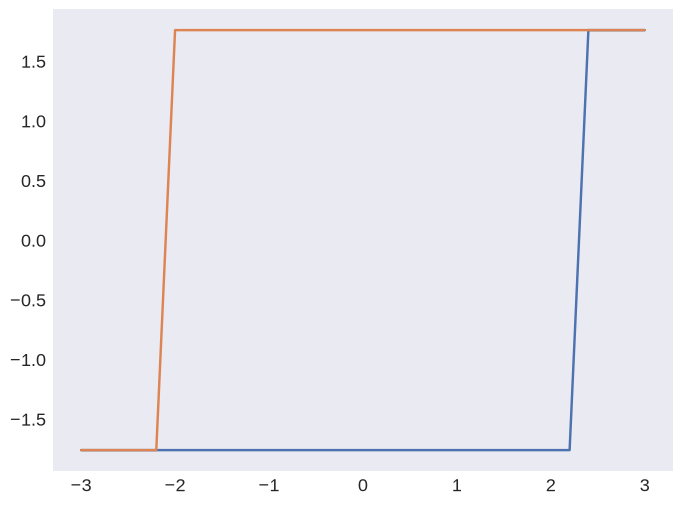

In [13]:
for index in [0, 1]:
    col = me.from_csv(f"loop/drive-0/hyst_loop-{index}/mammos_hysteresis.csv")
    plt.plot(col.B_ext_T.value, col.J_par_T.value)
plt.show()